# Denoising the real data

The best chain from `iteration2_search.ipynb` was chosen on synthetic data. On real data it marks about a third of the image as vehicles, because the 75th percentile threshold assumes that there is always the same amount of traffic. Here I build a chain for the **real** data.

Real data has no ground truth, so I made a small **hand-made reference** (`annotations/real_reference.json`) on the two assigned segments (09:10:52 and 09:12:22): 60 points on about 30 vehicles (clear and faint ones) and 9 quiet boxes with no vehicle. A mask is scored by:
- **hit** - share of the points with a mask pixel within 0.5 s (and within 0.25 s, to check how well the mask lies on the line),
- **false** - share of the quiet box pixels in the mask (false alarms),
- **density** - share of the whole image in the mask (lower = thinner lines),
- **speckle** - share of the mask in tiny blobs (noise left in the mask).

The third segment (09:18:52) is not used for choosing the chain, so it is a test.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # data and annotation paths are relative to the repository root

import glob
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DX = 5.106500953873407   # m between channels
DT = 0.0016              # s between samples
STEP = 25                # downsampling in time: 25 samples -> 1 row
DT2 = DT * STEP          # 0.04 s per row


def load_real(first_file, last_file):
    files = sorted(f for f in glob.glob('real-world-data/*.npy') if first_file <= f[-10:-4] <= last_file)
    return np.concatenate([np.load(f) for f in files]).astype(np.float64)


reference = json.load(open('annotations/real_reference.json'))
segments = {name: load_real(*name.split('-')) for name in ['091052-091242', '091222-091412']}   # assigned, used for tuning
third = {'091852-092042': load_real('091852', '092042')}                                        # third segment, test only

## 1. Steps

In [2]:
def band_pass(x, low, high):
    """FFT of every channel, zero outside [low, high] Hz, inverse FFT."""
    spectrum = np.fft.rfft(x, axis=0)
    freqs = np.fft.rfftfreq(len(x), DT)
    spectrum[(freqs < low) | (freqs > high)] = 0
    return np.fft.irfft(spectrum, n=len(x), axis=0)


def downsample(x):
    """Mean of every 25 samples (0.04 s)."""
    n = len(x) // STEP * STEP
    return x[:n].reshape(-1, STEP, x.shape[1]).mean(axis=1)


def envelope(x, low, high, gradient=False):
    """|band-passed signal| (or of its time derivative, as in iteration2_search.ipynb), averaged over 0.04 s."""
    y = band_pass(x, low, high)
    if gradient:
        y = np.gradient(y, axis=0)
    return downsample(np.abs(y))


def log_ratio(env):
    """log(value / median of its channel) - every channel gets the same scale."""
    return np.log(env / np.median(env, axis=0))


def remove_row_median(score):
    """Subtract the median of every row - removes short bursts that hit all channels at once (horizontal stripes)."""
    return score - np.median(score, axis=1, keepdims=True)


def score(x, low=40, high=312, gradient=False):
    return remove_row_median(log_ratio(envelope(x, low, high, gradient))).astype(np.float32)


def hysteresis(score, low, high):
    """Start from pixels > high and keep dilating (3x3) inside the pixels > low.
    Faint pixels survive only if they are connected to a strong part of a line."""
    seed = (score > high).astype(np.uint8)
    allowed = (score > low).astype(np.uint8)
    while True:
        grown = cv2.dilate(seed, np.ones((3, 3), np.uint8)) & allowed
        if np.array_equal(grown, seed):
            return seed.astype(bool)
        seed = grown


def fan_filter(score, min_kmh=10, max_kmh=130):
    """2D FFT of the image; a line moving with speed v lies on f = v * k, so keep only |f / k| in [min, max]."""
    h, w = score.shape
    mean = score.mean()
    padded = np.concatenate([score - mean, (score - mean)[:, ::-1][:, :64 - w]], axis=1)   # mirror to 64 channels
    f = np.fft.fftfreq(h, DT2)[:, None]
    k = np.fft.fftfreq(64, DX)[None, :]
    speed = np.abs(f) / np.maximum(np.abs(k), 1e-12) * 3.6
    keep = (speed >= min_kmh) & (speed <= max_kmh)
    keep[0, 0] = True
    return np.real(np.fft.ifft2(np.fft.fft2(padded) * keep))[:, :w] + mean


def best_chain(x):
    """Chosen chain: 40-312 Hz envelope -> log ratio -> row median -> Gaussian 0.2 s along time -> hysteresis 1.75x / 3.5x."""
    return hysteresis(cv2.GaussianBlur(score(x), (1, 5), 0), np.log(1.75), np.log(3.5))


def search_chain(x, percentile=75, ratio=None):
    """Best chain from iteration2_search.ipynb (band-pass 1-100 Hz, |gradient|, threshold, opening 5x1, closing 125x1)."""
    s = np.abs(np.gradient(band_pass(x, 1, 100), axis=0))
    if ratio is None:
        s = s - np.median(s, axis=0)
        mask = s > np.percentile(s, percentile)
    else:
        mask = s / np.median(s, axis=0) > ratio
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 1), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((125, 1), np.uint8))
    return downsample(mask.astype(np.float32)) > 0.5


def evaluate(mask, ref):
    hits = {}
    for tol in [0.5, 0.25]:
        r = int(tol / DT2)
        hits[tol] = np.mean([mask[max(int(round(t / DT2)) - r, 0):int(round(t / DT2)) + r + 1, c].any() for c, t in ref['points']])
    quiet = np.concatenate([mask[int(t0 / DT2):int(t1 / DT2), c0:c1 + 1].ravel() for c0, c1, t0, t1 in ref['quiet']])
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)   # only for the speckle score
    areas = stats[1:, cv2.CC_STAT_AREA]
    return {'hit': hits[0.5], 'hit 0.25 s': hits[0.25], 'false': quiet.mean(), 'density': mask.mean(),
            'speckle': areas[areas < 30].sum() / max(mask.sum(), 1)}


def show(ax, image, title, **kwargs):
    if image.dtype == bool:
        kwargs = {'cmap': 'gray', **kwargs}
    else:
        kwargs = {'cmap': 'magma', 'vmin': 0, 'vmax': np.percentile(image, 99.5), **kwargs}
    ax.imshow(image, aspect='auto', interpolation='nearest', extent=[0, image.shape[1] * DX, len(image) * DT2, 0], **kwargs)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('space [m]')

## 2. Hand-made reference

Red crosses = points on vehicles, green boxes = quiet areas. The points were placed by eye on the 0.5-5 Hz and 40-100 Hz images (background) and moved to the brightest pixel nearby.

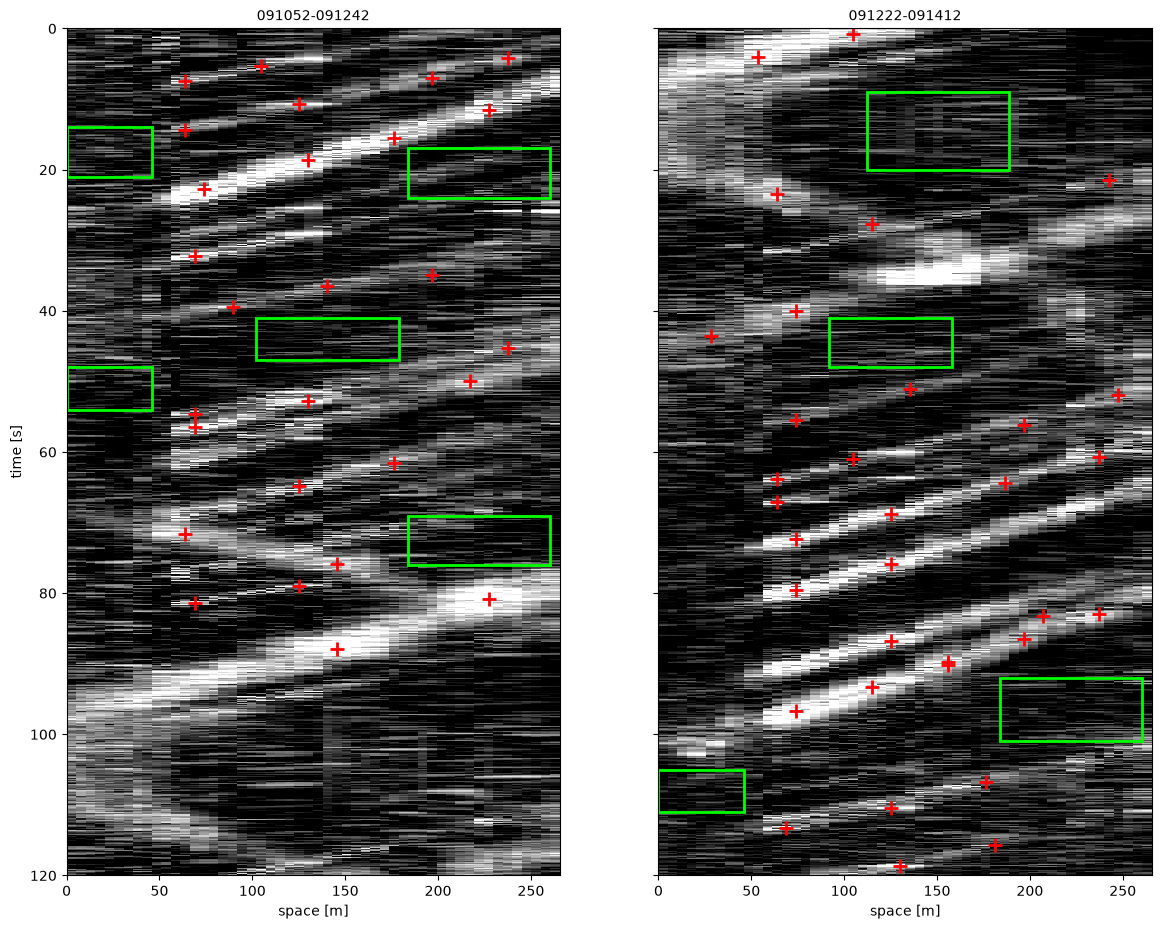

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 11), sharey=True)
for ax, (name, x) in zip(axes, segments.items()):
    parts = [np.clip(score(x, lo, hi), 0, None) for lo, hi in [(0.5, 5), (40, 100)]]
    show(ax, np.maximum(*[p / np.percentile(p, 99) for p in parts]), name, vmax=1, cmap='gray')
    points = np.array(reference[name]['points'])
    ax.plot((points[:, 0] + 0.5) * DX, points[:, 1], 'r+', ms=10, mew=2)
    for c0, c1, t0, t1 in reference[name]['quiet']:
        ax.add_patch(plt.Rectangle((c0 * DX, t0), (c1 - c0 + 1) * DX, t1 - t0, fill=False, ec='lime', lw=2))
axes[0].set_ylabel('time [s]')
plt.show()

## 3. Frequency analysis

The FFT of every channel, split into frequency bands. Every image is the envelope of one band (log ratio to the channel median, row median removed).

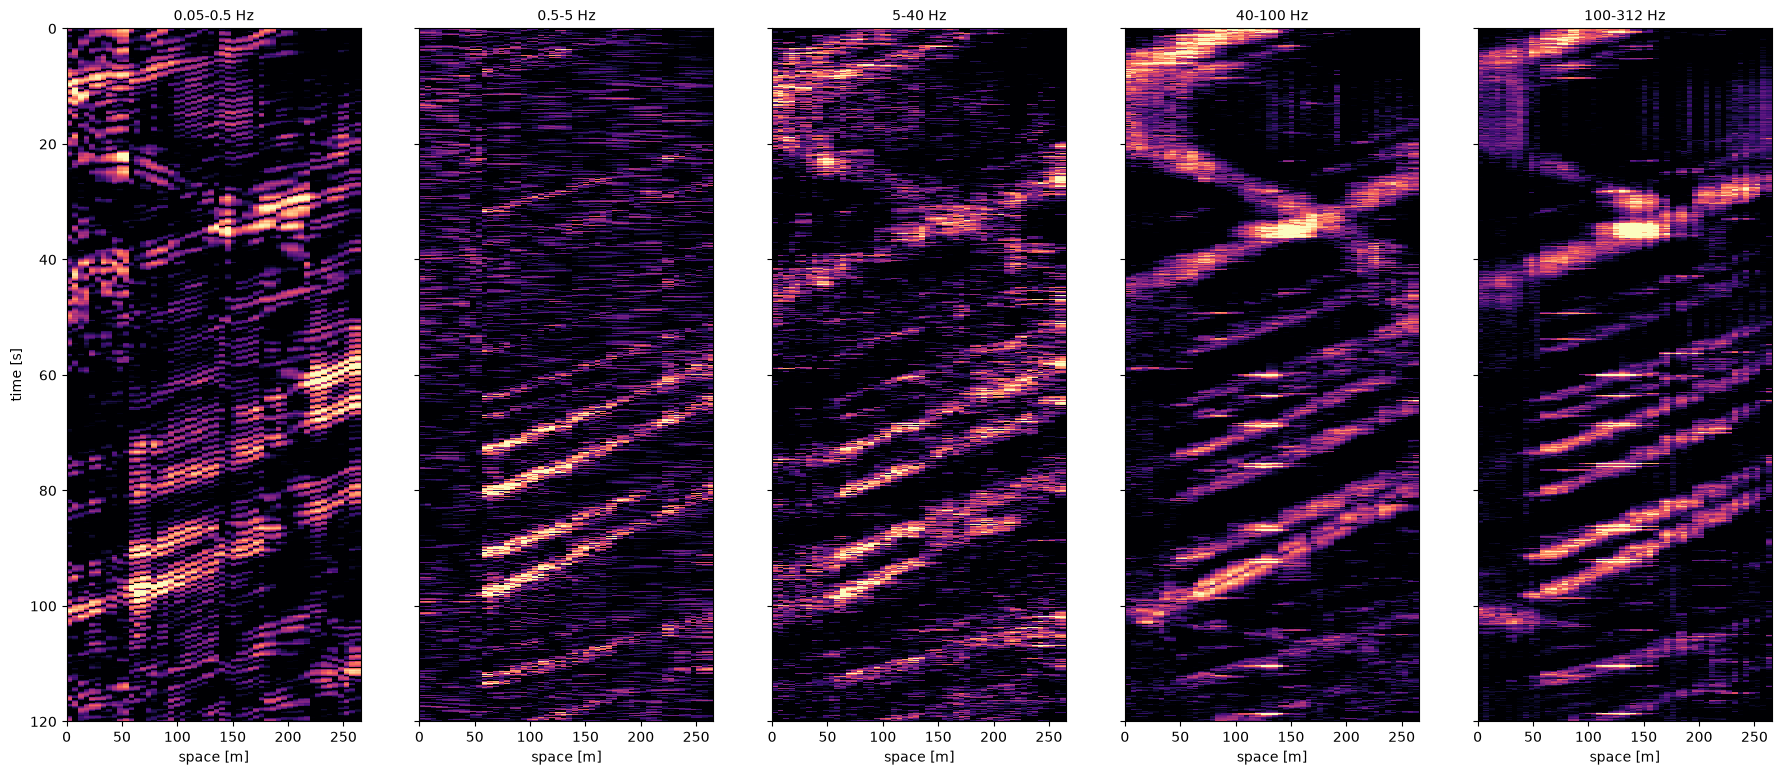

In [4]:
BANDS = [(0.05, 0.5), (0.5, 5), (5, 40), (40, 100), (100, 312)]
x = segments['091222-091412']
fig, axes = plt.subplots(1, len(BANDS), figsize=(22, 9), sharey=True)
for ax, (lo, hi) in zip(axes, BANDS):
    show(ax, score(x, lo, hi), f'{lo}-{hi} Hz')
axes[0].set_ylabel('time [s]')
plt.show()

To see at which frequencies the vehicles stand out, I compare the power spectrum of 1 s windows of one channel centred on the reference points (vehicles) with the windows inside the quiet boxes (background).

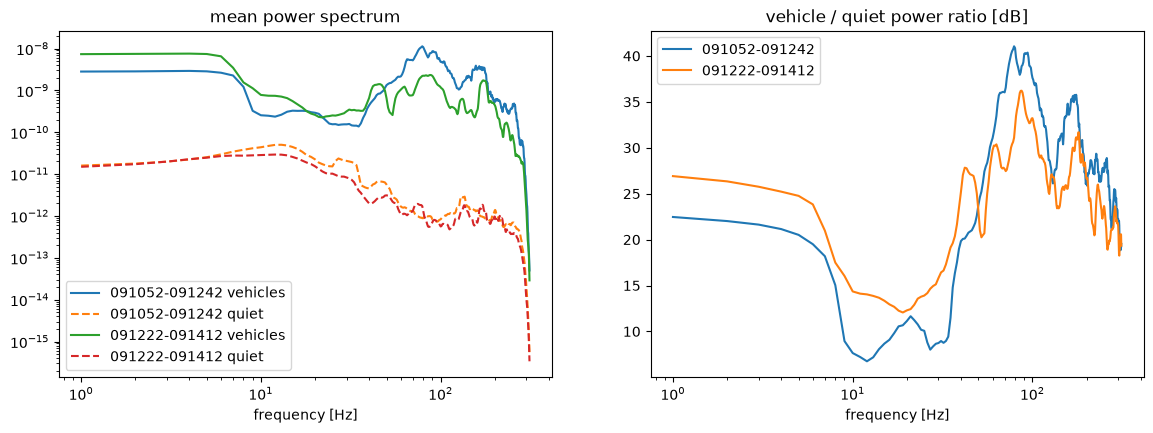

In [5]:
W = 625   # 1 s window
freqs = np.fft.rfftfreq(W, DT)
smooth = lambda p: np.convolve(p, np.ones(9) / 9, mode='same')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, x in segments.items():
    vehicle, quiet = [], []
    for c, t in reference[name]['points']:
        r = int(t / DT) - W // 2
        if r >= 0 and r + W <= len(x):
            vehicle.append(np.abs(np.fft.rfft(x[r:r + W, c] * np.hanning(W))) ** 2)
    for c0, c1, t0, t1 in reference[name]['quiet']:
        for c in range(c0, c1 + 1):
            for r in range(int(t0 / DT), int(t1 / DT) - W, W):
                quiet.append(np.abs(np.fft.rfft(x[r:r + W, c] * np.hanning(W))) ** 2)
    vehicle, quiet = smooth(np.mean(vehicle, axis=0)), smooth(np.mean(quiet, axis=0))
    axes[0].loglog(freqs[1:], vehicle[1:], label=f'{name} vehicles')
    axes[0].loglog(freqs[1:], quiet[1:], '--', label=f'{name} quiet')
    axes[1].semilogx(freqs[1:], 10 * np.log10(vehicle / quiet)[1:], label=name)
axes[0].set_title('mean power spectrum')
axes[1].set_title('vehicle / quiet power ratio [dB]')
for ax in axes:
    ax.set_xlabel('frequency [Hz]')
    ax.legend()
plt.show()

- Vehicles stand out most at **40-200 Hz** (35-40 dB). At 8-30 Hz the background is the strongest and the ratio drops to about 10 dB.
- Below 5 Hz the ratio is also high, but there are many horizontal stripes and the first 10 channels see almost nothing.
- The first 10 channels (0-50 m) are weak in every band, so lines often start only at about 50 m.

## 4. Search over chains

Every chain: **envelope of a band -> log ratio to the channel median -> remove the row median -> smoothing -> threshold**.
- band: 1-100 Hz |gradient| (as in `iteration2_search.ipynb`), 5-100, 20-100, 40-100 or 40-312 Hz,
- smoothing: none, median 5x5, Gaussian 0.2 s along time or Gaussian 3x3,
- threshold: one threshold (2, 2.5 or 3 x channel median) or **hysteresis** (pixels above the high threshold are seeds, then repeated dilation inside the pixels above the low one).

A chain is kept when it hits at least 96% of the points on **both** segments with at most 1.5% false alarms. The kept chains are sorted by hits within 0.25 s and by speckle.

In [6]:
SMOOTHING = {'none': lambda s: s,
             'median 5x5': lambda s: cv2.medianBlur(s, 5),
             'gauss 5 rows': lambda s: cv2.GaussianBlur(s, (1, 5), 0),
             'gauss 3x3': lambda s: cv2.GaussianBlur(s, (3, 3), 0)}
THRESHOLDS = {**{f'thr {t}': (lambda s, t=t: s > np.log(t)) for t in [2, 2.5, 3]},
              **{f'hyst {lo}-{hi}': (lambda s, lo=lo, hi=hi: hysteresis(s, np.log(lo), np.log(hi))) for lo, hi in [(1.5, 3), (1.75, 3.5), (2, 4)]}}
SEARCH_BANDS = {'1-100 grad': (1, 100, True), '5-100': (5, 100, False), '20-100': (20, 100, False),
                '40-100': (40, 100, False), '40-312': (40, 312, False)}

rows = []
for band_name, (lo, hi, grad) in SEARCH_BANDS.items():
    base = {name: score(x, lo, hi, grad) for name, x in segments.items()}
    for smooth_name, smooth_fn in SMOOTHING.items():
        for threshold_name, threshold in THRESHOLDS.items():
            for name, s in base.items():
                rows.append({'band': band_name, 'smoothing': smooth_name, 'threshold': threshold_name, 'segment': name,
                             **evaluate(threshold(smooth_fn(s)), reference[name])})
by_chain = pd.DataFrame(rows).groupby(['band', 'smoothing', 'threshold']).agg(
    hit_min=('hit', 'min'), hit_025=('hit 0.25 s', 'mean'), false=('false', 'mean'),
    density=('density', 'mean'), speckle=('speckle', 'mean'))
good = by_chain[(by_chain['hit_min'] >= 0.96) & (by_chain['false'] <= 0.015)]
print(f'{len(by_chain)} chains, {len(good)} kept')
display(good.sort_values(['hit_025', 'speckle'], ascending=[False, True]).head(8).round(3))

120 chains, 13 kept


hit_min  hit_025  false  density  \
band       smoothing    threshold                                         
40-312     gauss 5 rows hyst 1.75-3.5    0.963    0.981  0.007    0.242   
           gauss 3x3    hyst 1.75-3.5    0.963    0.966  0.004    0.238   
           none         hyst 1.75-3.5    0.963    0.966  0.014    0.242   
1-100 grad none         thr 2.5          1.000    0.951  0.010    0.175   
           gauss 3x3    hyst 1.5-3       0.963    0.948  0.012    0.282   
           none         hyst 2-4         0.963    0.948  0.007    0.208   
                        hyst 1.75-3.5    0.963    0.948  0.014    0.243   
40-312     median 5x5   thr 2            0.963    0.948  0.007    0.208   

                                       speckle  
band       smoothing    threshold               
40-312     gauss 5 rows hyst 1.75-3.5    0.003  
           gauss 3x3    hyst 1.75-3.5    0.004  
           none         hyst 1.75-3.5    0.017  
1-100 grad none         thr 2.5          0.100  
           gauss 3x3    hyst 1.5-3       0.001  
           none         hyst 2-4         0.015  
                        hyst 1.75-3.5    0.017  
40-312     median 5x5   thr 2            0.022

## 5. Comparison of the main candidates

,hit,hit 0.25 s,false,density,speckle
chain,,,,,
A: search chain (75th percentile),0.933,0.899,0.045,0.328,0.030
"B: search chain, 4 x channel median",0.786,0.771,0.015,0.188,0.046
"C: 1-100 Hz |grad|, row median, 2.5x",1.000,0.951,0.010,0.175,0.100
"D: like C + fan filter 10-130 km/h, 2x",0.862,0.843,0.006,0.205,0.016
E: like C without row median,0.951,0.902,0.020,0.216,0.080
"BEST: 40-312 Hz, row median, Gauss, hysteresis",0.981,0.981,0.007,0.242,0.003


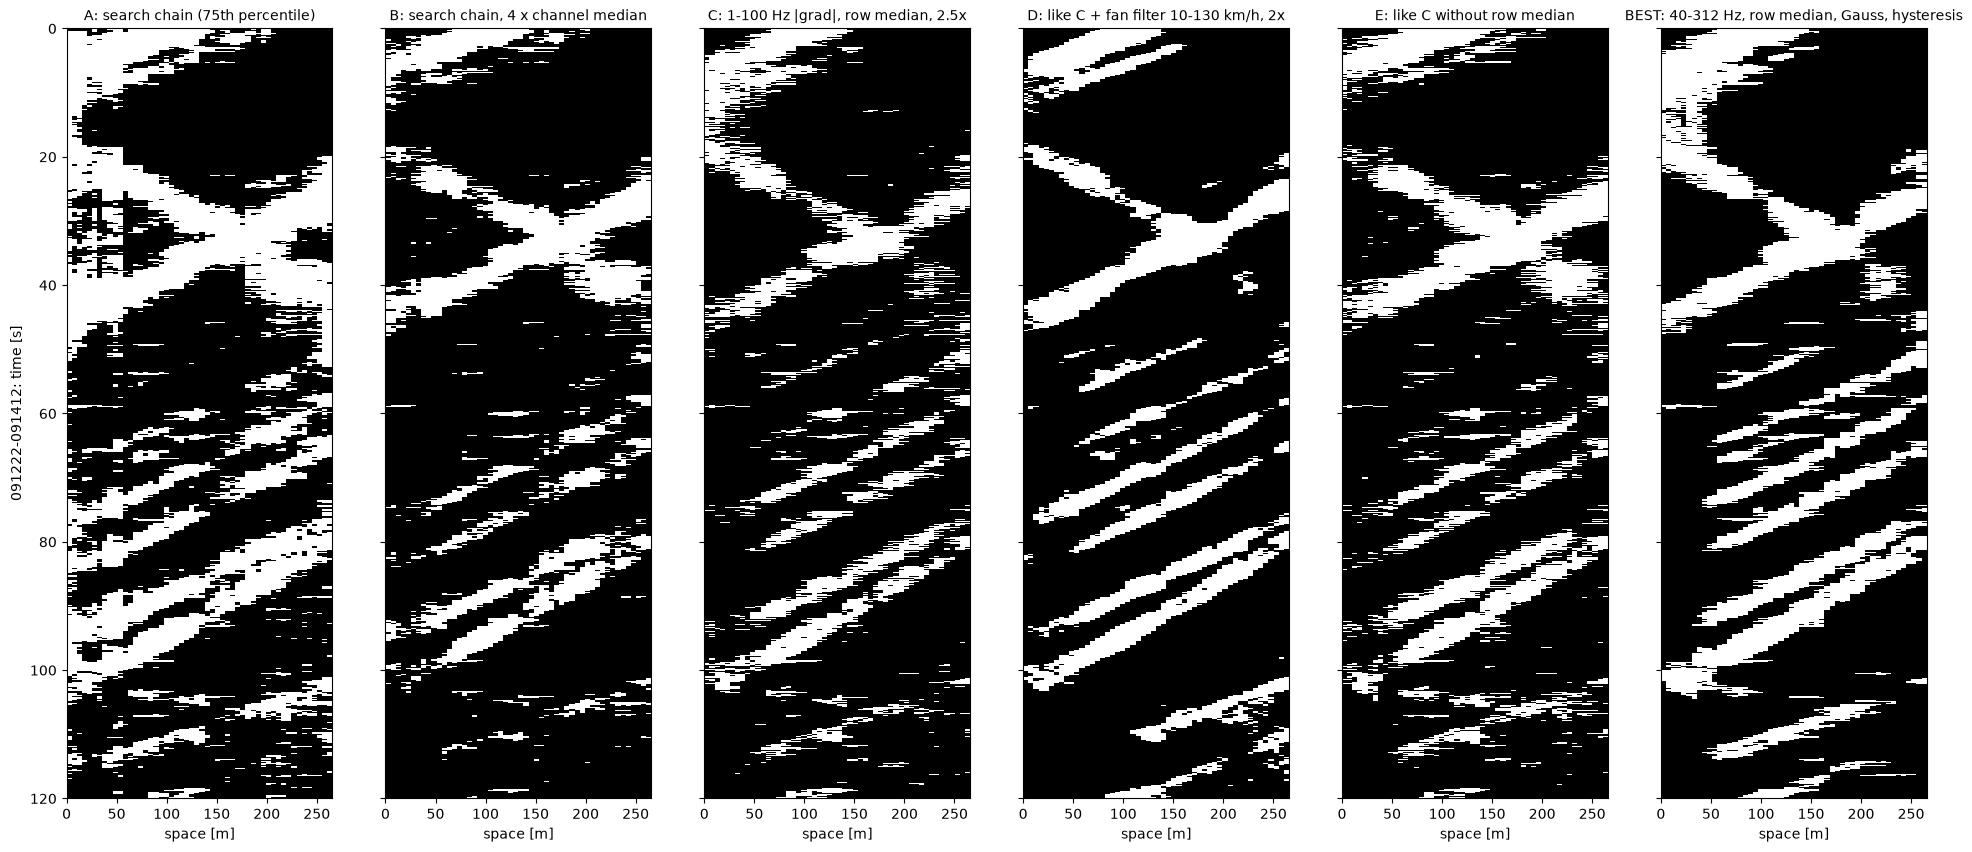

In [7]:
CANDIDATES = {
    'A: search chain (75th percentile)': lambda x: search_chain(x),
    'B: search chain, 4 x channel median': lambda x: search_chain(x, ratio=4),
    'C: 1-100 Hz |grad|, row median, 2.5x': lambda x: score(x, 1, 100, True) > np.log(2.5),
    'D: like C + fan filter 10-130 km/h, 2x': lambda x: fan_filter(score(x, 1, 100, True)) > np.log(2),
    'E: like C without row median': lambda x: log_ratio(envelope(x, 1, 100, True)) > np.log(2.5),
    'BEST: 40-312 Hz, row median, Gauss, hysteresis': best_chain,
}
masks = {(c, name): fn(x) for c, fn in CANDIDATES.items() for name, x in segments.items()}
table = pd.DataFrame({key: evaluate(m, reference[key[1]]) for key, m in masks.items()}).T
table.index.names = ['chain', 'segment']
display(table.groupby(level='chain', sort=False).mean().round(3))

name = '091222-091412'
fig, axes = plt.subplots(1, len(CANDIDATES), figsize=(4 * len(CANDIDATES), 10), sharey=True)
for ax, c in zip(axes, CANDIDATES):
    show(ax, masks[(c, name)], c)
axes[0].set_ylabel(f'{name}: time [s]')
plt.show()

- **A** marks a third of the image, **B** loses the faint cars.
- **Removing the row median** (C vs E) removes the horizontal stripes and lowers the false alarms.
- The **fan filter** (D, a mask in the 2D FFT that keeps only speeds 10-130 km/h) gives smooth lines, but the sharp mask makes "ghost" parallel lines and it removes slow vehicles.
- **BEST**: thin, continuous lines with almost no speckle, and faint cars survive thanks to the hysteresis. Changing its thresholds (1.5-2 low, 3-4 high) changes the scores gradually, without a sudden drop, so it does not depend on one lucky value.

## 6. Before and after

The chosen chain on all three segments. The third one (09:18:52) was not used for choosing the chain.

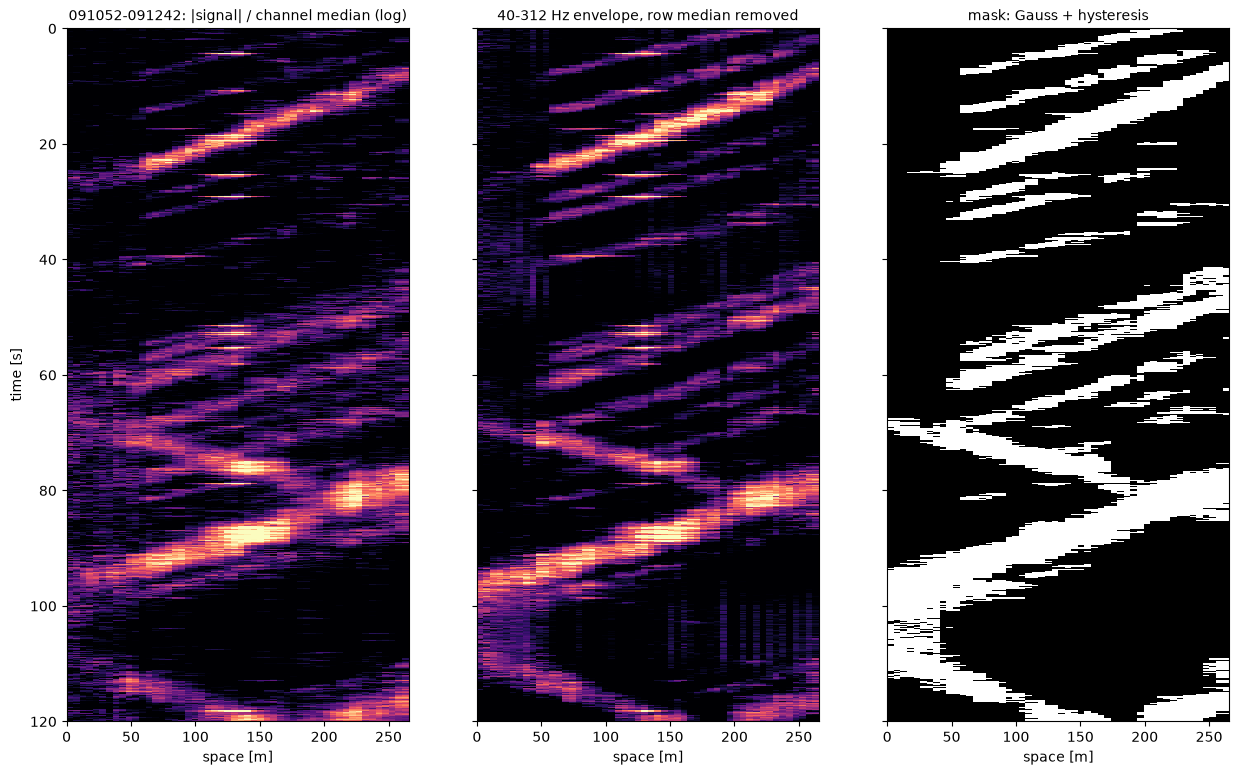

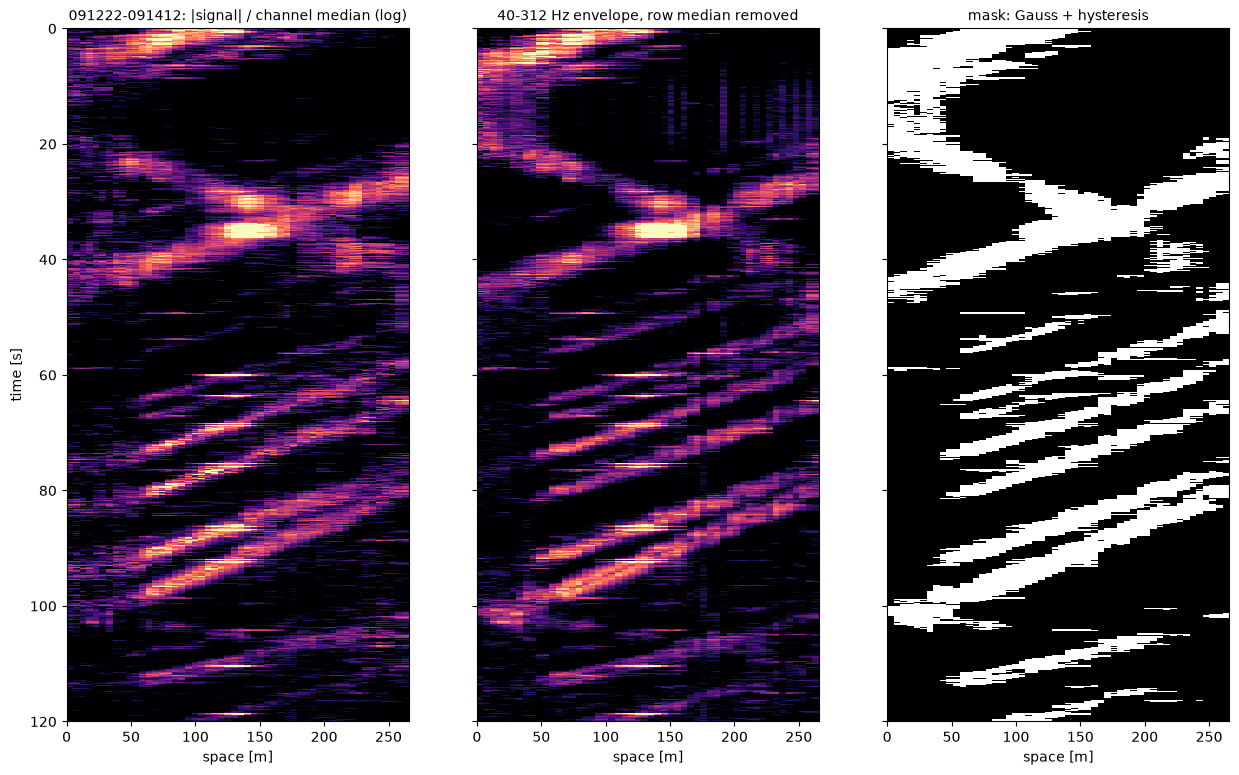

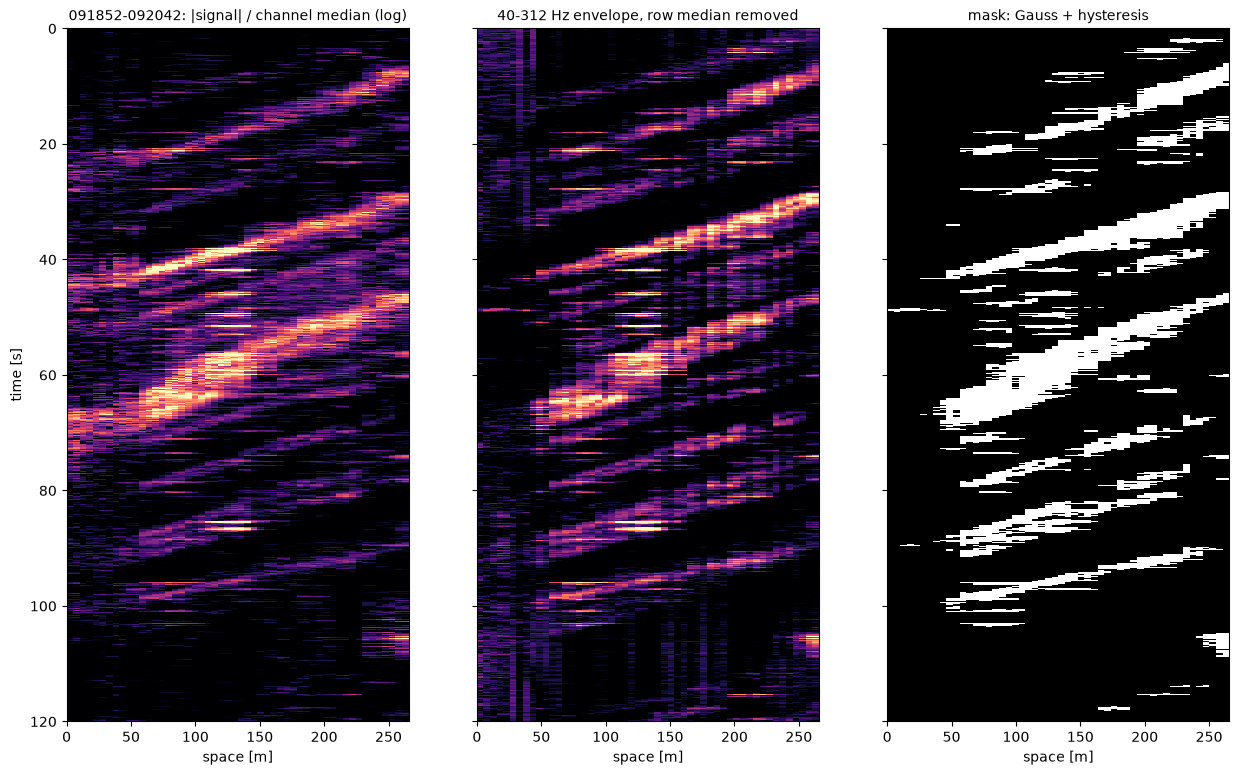

In [8]:
for name, x in {**segments, **third}.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 9), sharey=True)
    show(axes[0], log_ratio(downsample(np.abs(x))), f'{name}: |signal| / channel median (log)')
    show(axes[1], score(x), '40-312 Hz envelope, row median removed')
    show(axes[2], best_chain(x), 'mask: Gauss + hysteresis')
    axes[0].set_ylabel('time [s]')
    plt.show()

## 7. Whole recording (09:00:17 - 09:43:42)

The chosen chain on all 259 files, in pieces of 2 minutes (with one extra file on both sides, so the FFT has no edge effects at the cuts). One file pair is missing (gray).

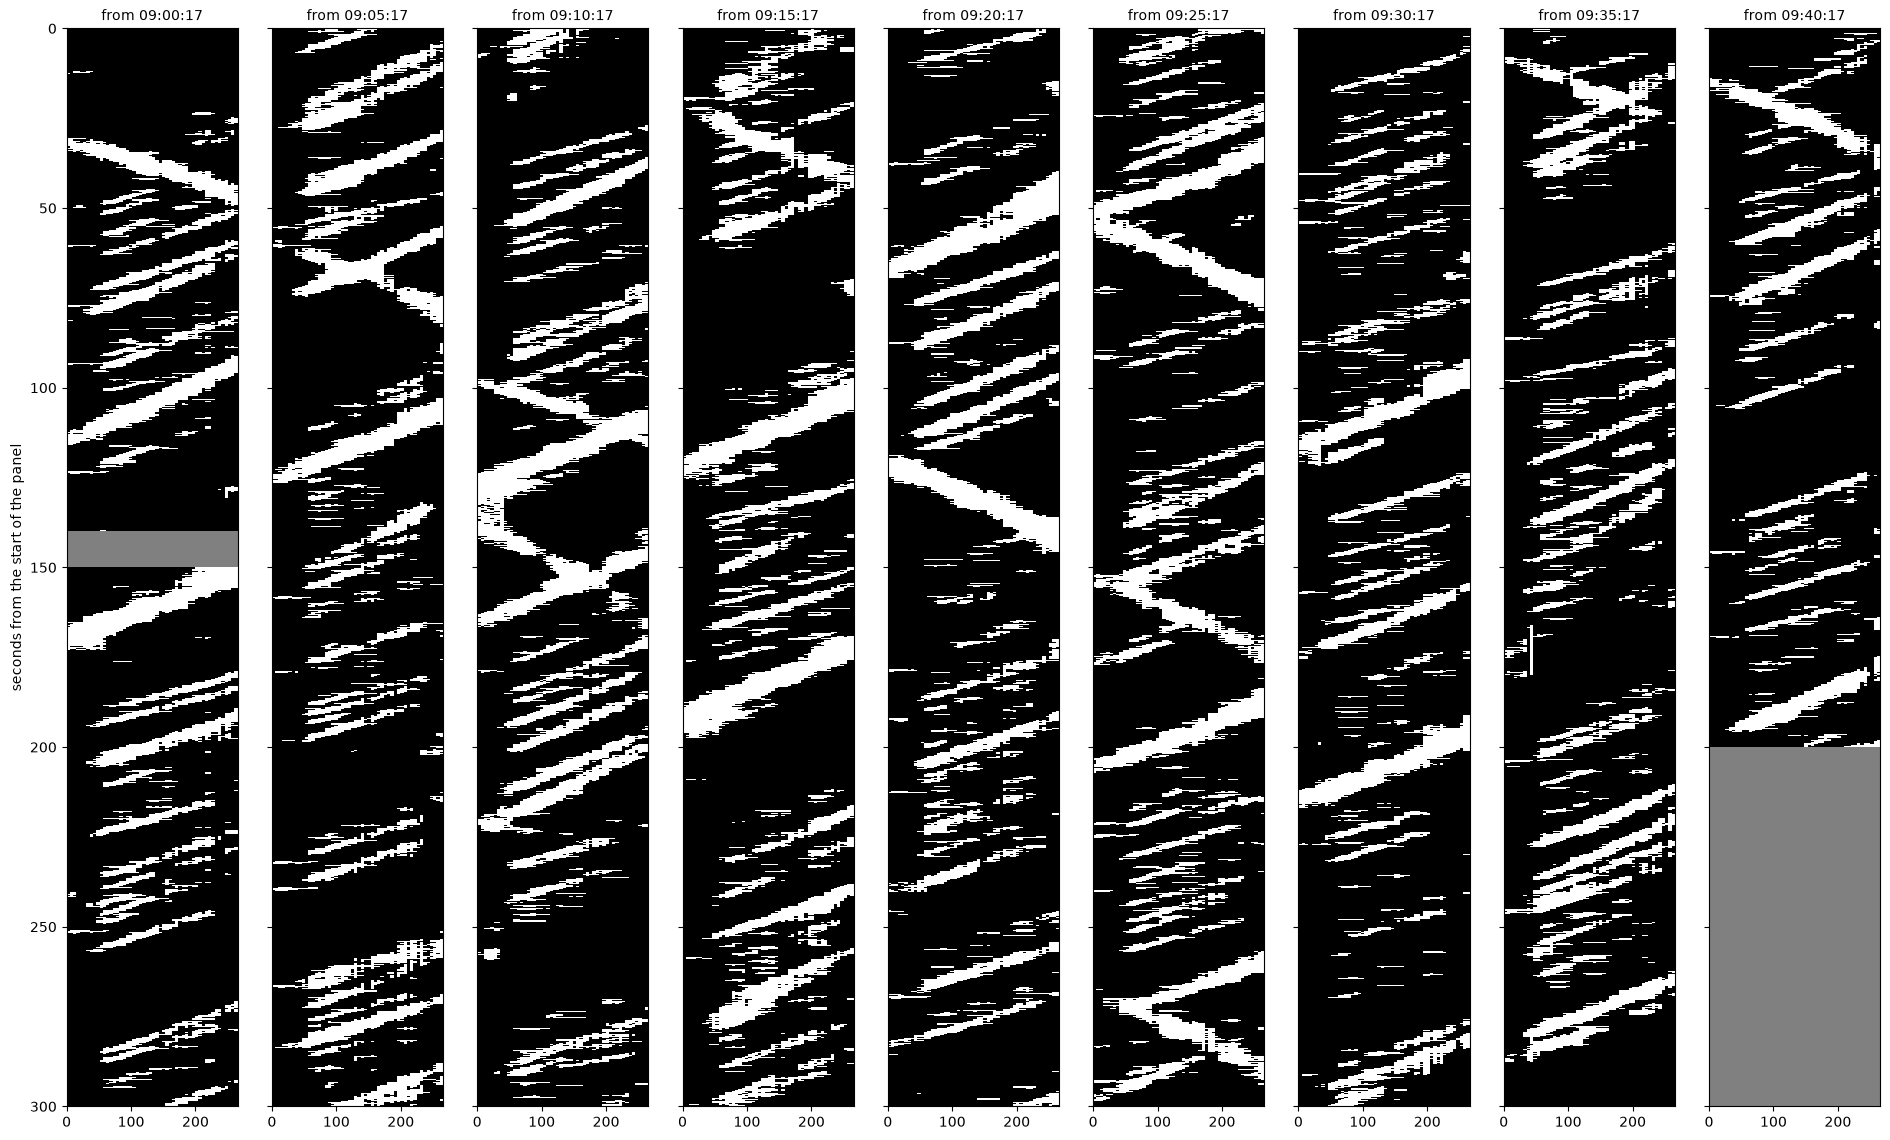

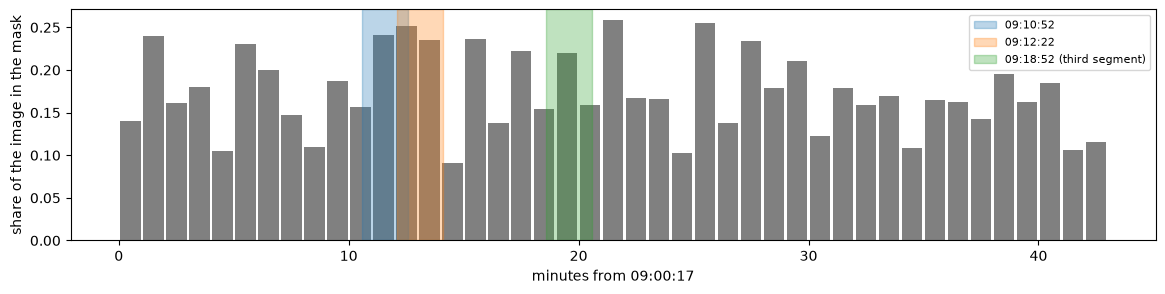

In [9]:
files = sorted(glob.glob('real-world-data/*.npy'))
seconds = np.array([int(f[-10:-8]) * 3600 + int(f[-8:-6]) * 60 + int(f[-6:-4]) for f in files])
ROWS_PER_FILE = 6250 // STEP
slots = (seconds - seconds[0]) // 10                    # place of every file on the time axis (10 s per file)
full_mask = np.full(((slots[-1] + 1) * ROWS_PER_FILE, 52), np.nan)
starts = [0] + [i for i in range(1, len(files)) if seconds[i] - seconds[i - 1] != 10] + [len(files)]
for a, b in zip(starts[:-1], starts[1:]):              # every part without missing files
    for c in range(a, b, 12):
        lo, hi = max(c - 1, a), min(c + 13, b)          # 12 files + 1 file margin on both sides
        mask = best_chain(np.concatenate([np.load(f) for f in files[lo:hi]]).astype(np.float64))
        for j in range(c - lo, min(c + 12, b) - lo):
            r = slots[lo + j] * ROWS_PER_FILE
            full_mask[r:r + ROWS_PER_FILE] = mask[j * ROWS_PER_FILE:(j + 1) * ROWS_PER_FILE]


def clock(s):
    return f'{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}'


PANEL = int(300 / DT2)   # 5 minutes per panel
n_panels = int(np.ceil(len(full_mask) / PANEL))
fig, axes = plt.subplots(1, n_panels, figsize=(2.6 * n_panels, 14), sharey=True)
for p, ax in enumerate(axes):
    part = np.nan_to_num(full_mask[p * PANEL:(p + 1) * PANEL], nan=0.5)
    ax.imshow(part, aspect='auto', cmap='gray', vmin=0, vmax=1, interpolation='nearest', extent=[0, 52 * DX, len(part) * DT2, 0])
    ax.set_title(f'from {clock(seconds[0] + p * 300)}', fontsize=10)
    ax.set_ylim(300, 0)
    ax.set_facecolor('gray')   # after the end of the recording
axes[0].set_ylabel('seconds from the start of the panel')
plt.show()

per_minute = np.nanmean(full_mask[:len(full_mask) // 1500 * 1500].reshape(-1, 1500 * 52), axis=1)   # 1500 rows = 60 s
fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(np.arange(len(per_minute)) + 0.5, per_minute, width=0.9, color='gray')
for (first, last), color, label in [(('091052', '091242'), 'tab:blue', '09:10:52'), (('091222', '091412'), 'tab:orange', '09:12:22'),
                                    (('091852', '092042'), 'tab:green', '09:18:52 (third segment)')]:
    to_min = lambda f: (int(f[:2]) * 3600 + int(f[2:4]) * 60 + int(f[4:]) - seconds[0]) / 60
    ax.axvspan(to_min(first), to_min(last) + 1 / 6, color=color, alpha=0.3, label=label)
ax.set_xlabel(f'minutes from {clock(seconds[0])}')
ax.set_ylabel('share of the image in the mask')
ax.legend(loc='upper right', fontsize=8)
plt.show()

- The chain works the same over the whole recording: **9-26% of the image per minute**, following the traffic (the search chain marks 33% everywhere).
- Visible: groups of cars (probably after traffic lights), thick tram lines every few minutes, both directions, crossings.
- Weak spots: very faint cars sometimes become dashed lines, the first 10 channels are weak everywhere and crossing vehicles join into one "X" (they are separated in `iteration4_detection.ipynb`).

## 8. Images for the detection

`iteration4_detection.ipynb` uses the **score image** (40-312 Hz envelope, log ratio, row median removed), not the final mask, because it needs the grey levels (how strong a vehicle is and where its line ends). The images are saved to `images/` for the three real segments and the 6 synthetic examples. The synthetic ground truth is downsampled with the **maximum** of every 25 samples, so a vehicle pixel stays a vehicle pixel.

In [10]:
os.makedirs('images', exist_ok=True)
images = {f'real_{name}': x for name, x in {**segments, **third}.items()}
for i in range(40, 46):
    images[f'synthetic_{i}'] = np.load(f'synthetic-data/{i}_signal.npy').astype(np.float64)
    gt = np.load(f'synthetic-data/{i}_ground_truth.npy')
    n = len(gt) // STEP * STEP
    np.save(f'images/synthetic_{i}_ground_truth.npy', gt[:n].reshape(-1, STEP, gt.shape[1]).max(axis=1))
for name, x in images.items():
    np.save(f'images/{name}.npy', score(x))
print(sorted(os.listdir('images')))

['real_091052-091242.npy', 'real_091222-091412.npy', 'real_091852-092042.npy', 'synthetic_40.npy', 'synthetic_40_ground_truth.npy', 'synthetic_41.npy', 'synthetic_41_ground_truth.npy', 'synthetic_42.npy', 'synthetic_42_ground_truth.npy', 'synthetic_43.npy', 'synthetic_43_ground_truth.npy', 'synthetic_44.npy', 'synthetic_44_ground_truth.npy', 'synthetic_45.npy', 'synthetic_45_ground_truth.npy']


## Summary

**Chosen chain:**
1. band-pass **40-312 Hz** in every channel (FFT) - where the vehicles stand out most from the background,
2. envelope: |signal| averaged over 0.04 s,
3. log(value / channel median) - every channel on the same scale,
4. subtract the **median of every row** - removes the horizontal stripes,
5. Gaussian blur 0.2 s along time,
6. **hysteresis threshold** 1.75x / 3.5x the channel median.

Compared with the search chain: false alarms down from about 4.5% to below 1%, image share from 33% to 24%, 96-100% of the reference points hit (search chain 93-94%), almost no speckle. It also works on the third segment and on the whole recording.

**Limitations:** the reference is hand-made (60 points, 9 quiet boxes) and checks hits and false alarms, not the exact shape of the lines; the first 10 channels are weak; stripes on only part of the channels stay; stopped vehicles stay in the mask (they are removed in the detection, which looks only for lines of at least 10 km/h).